In [31]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# machine Learning

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
#from sklearn.file import joblib

In [32]:
df = pd.read_csv("housing.csv")
df.head()

,RM,LSTAT,PTRATIO,MEDV
0,6.575,4.98,15.3,504000.0
1,6.421,9.14,17.8,453600.0
2,7.185,4.03,17.8,728700.0
3,6.998,2.94,18.7,701400.0
4,7.147,5.33,18.7,760200.0


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 489 entries, 0 to 488
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   RM       489 non-null    float64
 1   LSTAT    489 non-null    float64
 2   PTRATIO  489 non-null    float64
 3   MEDV     489 non-null    float64
dtypes: float64(4)
memory usage: 15.4 KB


In [34]:
df.describe()

,RM,LSTAT,PTRATIO,MEDV
count,489.000000,489.000000,489.000000,4.890000e+02
mean,6.240288,12.939632,18.516564,4.543429e+05
std,0.643650,7.081990,2.111268,1.653403e+05
min,3.561000,1.980000,12.600000,1.050000e+05
25%,5.880000,7.370000,17.400000,3.507000e+05
50%,6.185000,11.690000,19.100000,4.389000e+05
75%,6.575000,17.120000,20.200000,5.187000e+05
max,8.398000,37.970000,22.000000,1.024800e+06


In [35]:
df.isnull().sum()

RM         0
LSTAT      0
PTRATIO    0
MEDV       0
dtype: int64

In [36]:
# How to check for correlation

numeric_df = df.select_dtypes(include=np.number)
correletion = numeric_df.corr()
correletion['RM'].sort_values(ascending=False)

RM         1.000000
MEDV       0.697209
PTRATIO   -0.304559
LSTAT     -0.612033
Name: RM, dtype: float64

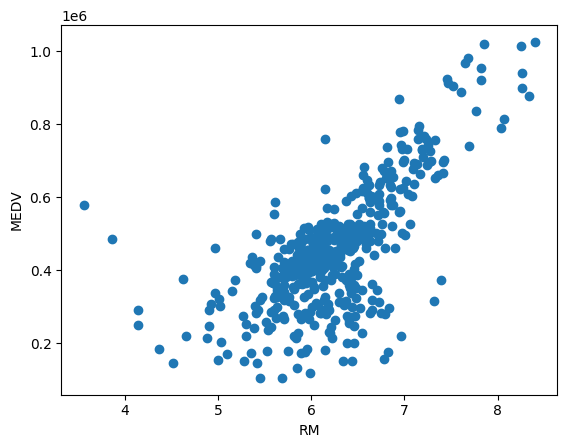

In [37]:
# How to check the relationship between dependent variable (grade) and independent variable (other features)
plt.scatter(df["RM"],df["MEDV"])
plt.xlabel("RM")
plt.ylabel("MEDV")
plt.show()

In [38]:
df['RM'].value_counts()

RM
6.229    3
6.127    3
6.167    3
6.405    3
6.417    3
        ..
6.425    1
6.069    1
5.682    1
5.786    1
6.998    1
Name: count, Length: 430, dtype: int64

In [39]:
df[df["PTRATIO"]>10]

,RM,LSTAT,PTRATIO,MEDV
0,6.575,4.98,15.3,504000.0
1,6.421,9.14,17.8,453600.0
2,7.185,4.03,17.8,728700.0
3,6.998,2.94,18.7,701400.0
4,7.147,5.33,18.7,760200.0
...,...,...,...,...
484,6.593,9.67,21.0,470400.0
485,6.120,9.08,21.0,432600.0
486,6.976,5.64,21.0,501900.0
487,6.794,6.48,21.0,462000.0


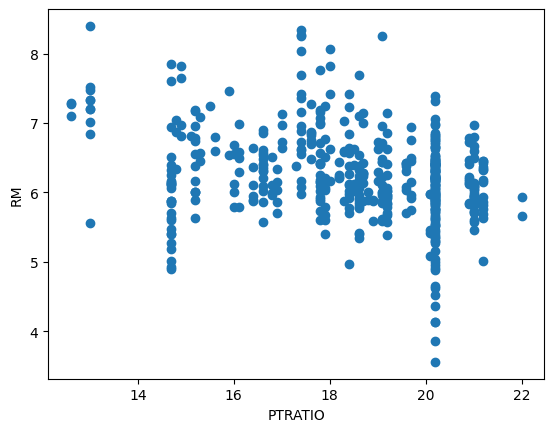

In [40]:
# Checking the relationship between the dependent (RM) and other independent (other features)
plt.scatter(df['PTRATIO'], df['RM'])
plt.xlabel("PTRATIO")
plt.ylabel("RM")
plt.show()

<Axes: xlabel='PTRATIO', ylabel='RM'>

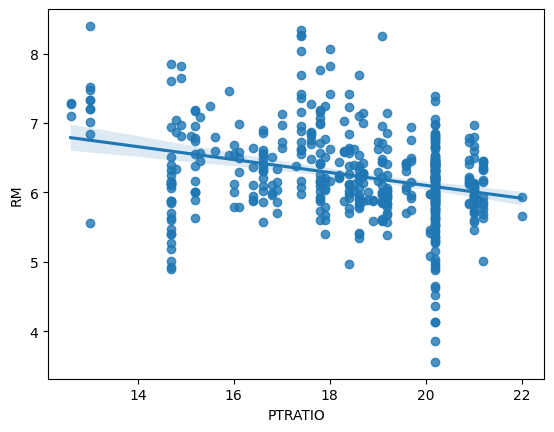

In [41]:
sns.regplot(data=df, x="PTRATIO", y="RM")

In [42]:
df.columns

Index(['RM', 'LSTAT', 'PTRATIO', 'MEDV'], dtype='object')

In [43]:
y = df["RM"]
x = df[['LSTAT', 'PTRATIO', 'MEDV']]

In [44]:
df.shape

(489, 4)

In [45]:
# Splitting the data into training and testing
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x,y, test_size=0.2)
print("Training Data Shape:", X_train.shape)
print("Test Data Shape:", X_test.shape)

Training Data Shape: (391, 3)
Test Data Shape: (98, 3)


In [46]:
# Feature Engineering
from sklearn.preprocessing import StandardScaler
#intailize
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [47]:
# Training the Model: Linear Regression Model
from sklearn.linear_model import LinearRegression
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [48]:
# Prediction
linear_predictions = linear_model.predict(X_test_scaled)
linear_predictions

array([6.67855641, 5.71590102, 6.4194377 , 6.37577979, 6.24823102,
       6.77306077, 6.31748759, 5.32595514, 6.46807146, 5.53984915,
       6.07560736, 6.35360472, 6.50044581, 6.22250982, 5.91434472,
       6.44909858, 6.43182486, 5.53907204, 5.42070825, 6.41292978,
       6.00411155, 6.0993054 , 5.70892458, 6.90629101, 5.96744918,
       6.26330892, 6.16515619, 5.72008354, 5.8008376 , 6.49996785,
       6.07384866, 6.33126405, 7.10209818, 7.0275673 , 6.66257176,
       6.08652879, 6.28168882, 6.28276519, 7.55288703, 6.07610318,
       5.74181875, 6.63434519, 6.47441919, 5.64448044, 6.53544512,
       5.88895171, 6.13628819, 6.34262909, 7.17931607, 6.05545788,
       6.10782703, 5.57671861, 5.77452421, 6.63110908, 7.05040083,
       5.93696056, 6.09586563, 5.81216284, 6.22158118, 5.28772378,
       6.281287  , 6.1334862 , 5.52660869, 6.22504576, 5.46485571,
       7.47247977, 5.37455785, 5.9678828 , 5.55545433, 5.93763672,
       5.66883973, 6.38970395, 5.85219813, 6.54748094, 6.52556

In [49]:
# Training the Random Forest Model
from sklearn.ensemble import RandomForestRegressor
random_forest_model = RandomForestRegressor()
random_forest_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [50]:
# Prediction
random_forest_predictions = random_forest_model.predict(X_test)
random_forest_predictions

array([6.63885, 5.99968, 6.29586, 6.21956, 5.79976, 6.85065, 5.87885,
       5.97476, 6.56373, 4.90111, 6.00066, 6.00605, 6.36099, 5.99501,
       6.14943, 6.3994 , 6.41698, 6.25718, 5.85357, 6.53846, 6.35916,
       6.05142, 5.87109, 6.94429, 5.87635, 6.04269, 5.91905, 5.80732,
       5.83737, 6.36565, 5.73381, 6.25876, 7.16783, 7.27931, 6.74713,
       6.26828, 6.04902, 6.21368, 7.81736, 5.75273, 5.72611, 6.70244,
       6.35578, 6.13338, 6.38129, 5.9714 , 5.96161, 6.35346, 7.09787,
       5.11687, 5.91517, 6.31957, 6.41715, 6.76186, 7.01929, 5.66524,
       5.90444, 5.67221, 6.15293, 5.06463, 6.44624, 5.97407, 6.1672 ,
       6.13776, 5.98505, 7.77622, 5.41233, 5.8712 , 5.77696, 5.91834,
       6.11887, 6.319  , 5.72858, 6.10773, 7.08785, 6.14331, 6.25908,
       4.83157, 6.1656 , 5.89439, 6.06397, 6.24795, 4.80718, 6.23908,
       5.67457, 6.88717, 5.45609, 5.27137, 5.86145, 6.19245, 6.25098,
       6.79184, 6.76353, 6.24084, 6.58569, 6.33129, 6.45157, 6.70454])

In [60]:
# Model Evaluation Metrics
from sklearn.metrics import mean_squared_error,r2_score
#RSquared for Linear Regression
linear_regression_r2=r2_score(y_test, linear_predictions)
#mean squared error for Linear Regression
linear_regression_mse=mean_squared_error(y_test, linear_predictions)
print("linear regression Rsquared:", linear_regression_r2)
print("linear regression mean squared error:", linear_regression_mse)

linear regression Rsquared: 0.441352175337811
linear regression mean squared error: 0.20556152335791286


In [65]:
from sklearn.metrics import mean_squared_error,r2_score
# RSquared for Random Forest Regressor
Random_Forest_Regressor_r2 = r2_score(y_test, random_forest_predictions)
# mean squared error for Random Forest Regressor
Random_Forest_Regressor_mse = mean_squared_error(y_test, random_forest_predictions)
print("Random Forest Regressor:",Random_Forest_Regressor_r2)
print("Random Forest Regressor:",Random_Forest_Regressor_mse)

Random Forest Regressor: 0.5178554585756391
Random Forest Regressor: 0.1774111739785712
